# Denglisch Processed Data - Inspection & Analysis

Inspection, visualization, and analysis of the **converted/cleaned** Denglisch data produced by
the project pipeline (`src/corpus_converter.py` -> `src/preprocess.py`), found in
`data/processed/`:

- `train.json`, `val.json`, `test.json` - sentence-level records of the form
  `{"tokens": [...], "labels": [...], "comment_id": "..."}` with the project's three target
  labels (`DE`, `EN`, `NEUT`)
- `char_vocab.json` - the character vocabulary built from the training split

Unlike `data_inspection.ipynb` (which looks at the *original* Denglisch Corpus release), this
notebook verifies that preprocessing behaved as intended: labels were mapped correctly, splits
don't leak Reddit comments across train/val/test, and the resulting tensors/vocabulary are
sane for the 1D-TCN model to train on.

Sections:
1. Load processed splits and the character vocabulary
2. Schema & integrity checks
3. Comment-level split-leakage check
4. Label distribution across splits
5. Sentence-length distribution
6. Token-length distribution vs. `max_word_len`
7. Character vocabulary composition
8. Code-switching density/switch-point analysis
9. Cross-check against the raw-corpus conversion counts


In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

DATA_PROCESSED = Path("../data/processed")
SPLIT_PATHS = {
    "train": DATA_PROCESSED / "train.json",
    "val": DATA_PROCESSED / "val.json",
    "test": DATA_PROCESSED / "test.json",
}
CHAR_VOCAB_PATH = DATA_PROCESSED / "char_vocab.json"

for name, path in {**SPLIT_PATHS, "char_vocab": CHAR_VOCAB_PATH}.items():
    assert path.exists(), f"Missing {path} - run src/preprocess.py first (see README)."

print("All processed files found:", ", ".join(p.name for p in [*SPLIT_PATHS.values(), CHAR_VOCAB_PATH]))


All processed files found: train.json, val.json, test.json, char_vocab.json


## 1. Load Processed Splits and Character Vocabulary

In [2]:
def load_split(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

splits = {name: load_split(path) for name, path in SPLIT_PATHS.items()}
with open(CHAR_VOCAB_PATH, encoding="utf-8") as f:
    char_vocab = json.load(f)

for name, records in splits.items():
    print(f"{name:>5}: {len(records):5d} sentences")
print(f"\nCharacter vocabulary size (incl. <PAD>/<UNK>): {len(char_vocab)}")


train:  3347 sentences
  val:   405 sentences
 test:   449 sentences

Character vocabulary size (incl. <PAD>/<UNK>): 159


## 2. Schema & Integrity Checks

Verifies every record has matching `tokens`/`labels` lengths, every label is one of the three
project target labels, and reports basic per-split token counts.

In [3]:
VALID_LABELS = {"DE", "EN", "NEUT"}

def check_split(name, records):
    length_mismatches = 0
    invalid_labels = Counter()
    missing_comment_id = 0
    total_tokens = 0

    for record in records:
        tokens, labels = record["tokens"], record["labels"]
        if len(tokens) != len(labels):
            length_mismatches += 1
        invalid_labels.update(l for l in labels if l not in VALID_LABELS)
        if "comment_id" not in record:
            missing_comment_id += 1
        total_tokens += len(tokens)

    print(f"[{name}] sentences={len(records)}  tokens={total_tokens}  "
          f"length_mismatches={length_mismatches}  invalid_labels={dict(invalid_labels)}  "
          f"missing_comment_id={missing_comment_id}")
    return total_tokens

token_totals = {name: check_split(name, records) for name, records in splits.items()}


[train] sentences=3347  tokens=59196  length_mismatches=0  invalid_labels={}  missing_comment_id=0
[val] sentences=405  tokens=7042  length_mismatches=0  invalid_labels={}  missing_comment_id=0
[test] sentences=449  tokens=7418  length_mismatches=0  invalid_labels={}  missing_comment_id=0


## 3. Comment-Level Split-Leakage Check

The paper requires that sentences from the same Reddit comment never appear in more than one
split. This recomputes the same check used in `tests/test_preprocess.py` directly on the
processed files.

In [4]:
comment_ids = {
    name: {r.get("comment_id") for r in records if r.get("comment_id") is not None}
    for name, records in splits.items()
}

for name, ids in comment_ids.items():
    print(f"{name:>5}: {len(ids)} unique comment_id values")

overlap_train_val = comment_ids["train"] & comment_ids["val"]
overlap_train_test = comment_ids["train"] & comment_ids["test"]
overlap_val_test = comment_ids["val"] & comment_ids["test"]

print("\nOverlap train/val:  ", len(overlap_train_val))
print("Overlap train/test: ", len(overlap_train_test))
print("Overlap val/test:   ", len(overlap_val_test))
assert not (overlap_train_val or overlap_train_test or overlap_val_test), "Comment leaked across splits!"
print("\nNo comment-level leakage detected across train/val/test.")


train: 769 unique comment_id values
  val: 96 unique comment_id values
 test: 97 unique comment_id values

Overlap train/val:   0
Overlap train/test:  0
Overlap val/test:    0

No comment-level leakage detected across train/val/test.


## 4. Label Distribution Across Splits

In [5]:
def label_counts(records):
    counter = Counter()
    for record in records:
        counter.update(record["labels"])
    return counter

label_df = pd.DataFrame({name: label_counts(records) for name, records in splits.items()}).fillna(0).astype(int)
label_df = label_df.reindex(["DE", "EN", "NEUT"])
label_pct_df = (label_df / label_df.sum(axis=0) * 100).round(2)

print("Token counts per label per split:")
print(label_df)
print("\nPercentage of tokens per label per split:")
print(label_pct_df)


Token counts per label per split:
      train   val  test
DE    24312  3177  3048
EN    24725  2773  3119
NEUT  10159  1092  1251

Percentage of tokens per label per split:
      train    val   test
DE    41.07  45.12  41.09
EN    41.77  39.38  42.05
NEUT  17.16  15.51  16.86


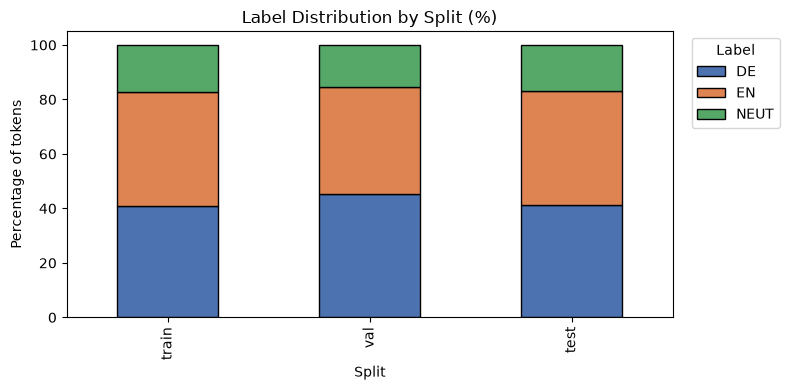

In [6]:
ax = label_pct_df.T.plot(kind="bar", stacked=True, color=["#4C72B0", "#DD8452", "#55A868"], edgecolor="black")
ax.set_title("Label Distribution by Split (%)")
ax.set_xlabel("Split")
ax.set_ylabel("Percentage of tokens")
ax.legend(title="Label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 5. Sentence-Length Distribution

Tokens-per-sentence distribution for each split; similar distributions across splits would
indicate the comment-level split did not introduce systematic sentence-length bias.

train: {'count': 3347.0, 'mean': 17.686286226471466, 'std': 19.809226120453864, 'min': 1.0, '25%': 8.0, '50%': 14.0, '75%': 22.0, 'max': 605.0}
  val: {'count': 405.0, 'mean': 17.387654320987654, 'std': 14.888374948028462, 'min': 1.0, '25%': 8.0, '50%': 14.0, '75%': 22.0, 'max': 184.0}
 test: {'count': 449.0, 'mean': 16.521158129175948, 'std': 14.010363590623095, 'min': 1.0, '25%': 8.0, '50%': 13.0, '75%': 21.0, 'max': 123.0}


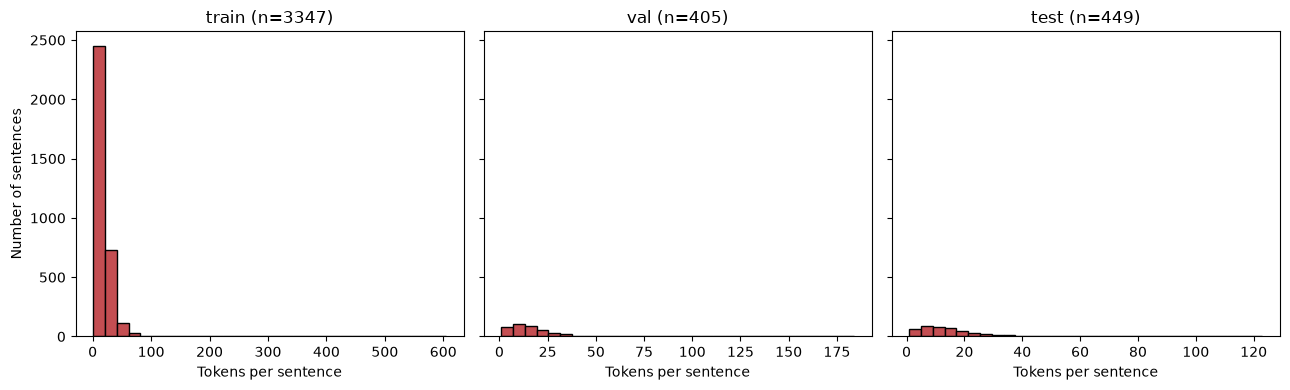

In [7]:
sentence_lengths = {name: [len(r["tokens"]) for r in records] for name, records in splits.items()}

for name, lengths in sentence_lengths.items():
    print(f"{name:>5}: {pd.Series(lengths).describe().to_dict()}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, lengths) in zip(axes, sentence_lengths.items()):
    ax.hist(lengths, bins=30, color="#C44E52", edgecolor="black")
    ax.set_title(f"{name} (n={len(lengths)})")
    ax.set_xlabel("Tokens per sentence")
axes[0].set_ylabel("Number of sentences")
plt.tight_layout()
plt.show()


## 6. Token-Length Distribution vs. `max_word_len`

count    59196.000000
mean         4.593503
std          6.372193
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max       1233.000000
dtype: float64

Tokens longer than max_word_len=20: 239 (0.404% of training tokens, will be truncated)


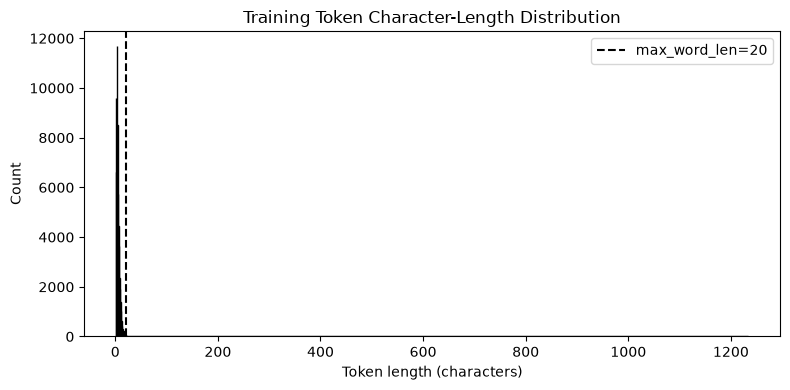

In [8]:
MAX_WORD_LEN = 20  # default from config.yaml / dataset.py

train_token_lengths = pd.Series([len(tok) for r in splits["train"] for tok in r["tokens"]])
print(train_token_lengths.describe())

truncated = (train_token_lengths > MAX_WORD_LEN).sum()
print(f"\nTokens longer than max_word_len={MAX_WORD_LEN}: {truncated} "
      f"({100 * truncated / len(train_token_lengths):.3f}% of training tokens, will be truncated)")

fig, ax = plt.subplots()
ax.hist(train_token_lengths, bins=range(1, int(train_token_lengths.max()) + 2), color="#55A868", edgecolor="black")
ax.axvline(MAX_WORD_LEN, color="black", linestyle="--", label=f"max_word_len={MAX_WORD_LEN}")
ax.set_title("Training Token Character-Length Distribution")
ax.set_xlabel("Token length (characters)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Character Vocabulary Composition

Buckets each vocabulary entry to understand what kind of characters the `CharCNN` embedding
table needs to cover (ASCII letters, digits, German-specific letters, punctuation, or other
Unicode such as emoji picked up from Reddit text).

other-unicode (emoji/accents/etc.)    63
ascii-letter                          52
ascii-punct/symbol                    30
digit                                 11
special                                2
german-specific                        1
dtype: int64


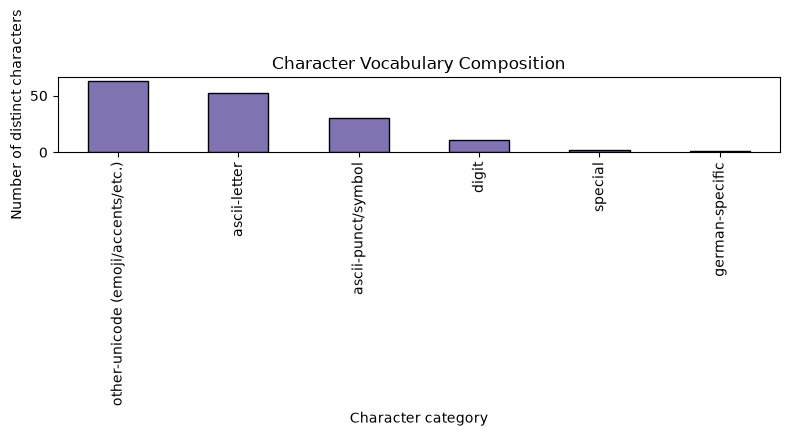

In [9]:
GERMAN_SPECIFIC = set("???????")
SPECIAL_TOKENS = {"<PAD>", "<UNK>"}

def bucket_char(ch):
    if ch in SPECIAL_TOKENS:
        return "special"
    if ch in GERMAN_SPECIFIC:
        return "german-specific"
    if ch.isascii() and ch.isalpha():
        return "ascii-letter"
    if ch.isdigit():
        return "digit"
    if ch.isascii() and not ch.isalnum():
        return "ascii-punct/symbol"
    return "other-unicode (emoji/accents/etc.)"

bucket_counts = Counter(bucket_char(ch) for ch in char_vocab.keys())
bucket_series = pd.Series(bucket_counts).sort_values(ascending=False)
print(bucket_series)

ax = bucket_series.plot(kind="bar", color="#8172B2", edgecolor="black")
ax.set_title("Character Vocabulary Composition")
ax.set_xlabel("Character category")
ax.set_ylabel("Number of distinct characters")
plt.tight_layout()
plt.show()


In [10]:
def out_of_vocab_rate(records, vocab):
    total_chars, oov_chars = 0, 0
    for record in records:
        for token in record["tokens"]:
            for ch in token:
                total_chars += 1
                if ch not in vocab:
                    oov_chars += 1
    return oov_chars, total_chars

for name in ["val", "test"]:
    oov, total = out_of_vocab_rate(splits[name], char_vocab)
    print(f"{name:>5}: {oov}/{total} characters ({100 * oov / total:.3f}%) fall back to <UNK> "
          f"(not seen in the training vocabulary)")


  val: 13/32750 characters (0.040%) fall back to <UNK> (not seen in the training vocabulary)
 test: 4/33536 characters (0.012%) fall back to <UNK> (not seen in the training vocabulary)


## 8. Code-Switching Density & Switch-Point Analysis

Beyond raw label counts, two sentence-level metrics better capture *how* code-switched the data
is: the share of non-neutral tokens that are English vs. German, and the number of DE<->EN
*switch points* (adjacent non-neutral tokens whose language differs). This mirrors the paper's
emphasis on identifying language-switch boundaries rather than only classifying individual
tokens.

In [11]:
def switch_points(labels):
    non_neutral = [l for l in labels if l != "NEUT"]
    return sum(1 for a, b in zip(non_neutral, non_neutral[1:]) if a != b)

def analyze_switching(records):
    rows = []
    for r in records:
        labels = r["labels"]
        non_neutral = [l for l in labels if l != "NEUT"]
        en_share = non_neutral.count("EN") / len(non_neutral) if non_neutral else float("nan")
        rows.append({
            "num_tokens": len(labels),
            "num_switches": switch_points(labels),
            "en_share": en_share,
            "is_code_switched": len(set(non_neutral)) > 1,
        })
    return pd.DataFrame(rows)

switch_dfs = {name: analyze_switching(records) for name, records in splits.items()}

for name, df in switch_dfs.items():
    pct_switched = 100 * df["is_code_switched"].mean()
    avg_switches = df.loc[df["is_code_switched"], "num_switches"].mean()
    print(f"{name:>5}: {pct_switched:.1f}% of sentences contain both DE and EN tokens; "
          f"avg {avg_switches:.2f} switch points among code-switched sentences")


train: 36.5% of sentences contain both DE and EN tokens; avg 2.58 switch points among code-switched sentences
  val: 35.8% of sentences contain both DE and EN tokens; avg 2.70 switch points among code-switched sentences
 test: 31.6% of sentences contain both DE and EN tokens; avg 2.26 switch points among code-switched sentences


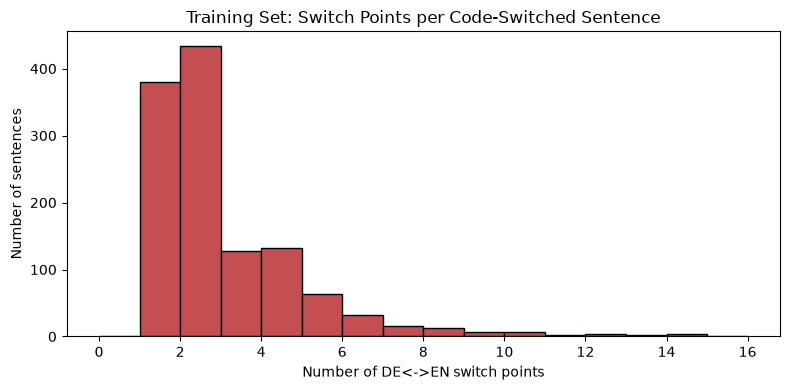

In [12]:
fig, ax = plt.subplots()
train_switches = switch_dfs["train"].loc[switch_dfs["train"]["is_code_switched"], "num_switches"]
ax.hist(train_switches, bins=range(0, int(train_switches.max()) + 2), color="#C44E52", edgecolor="black")
ax.set_title("Training Set: Switch Points per Code-Switched Sentence")
ax.set_xlabel("Number of DE<->EN switch points")
ax.set_ylabel("Number of sentences")
plt.tight_layout()
plt.show()


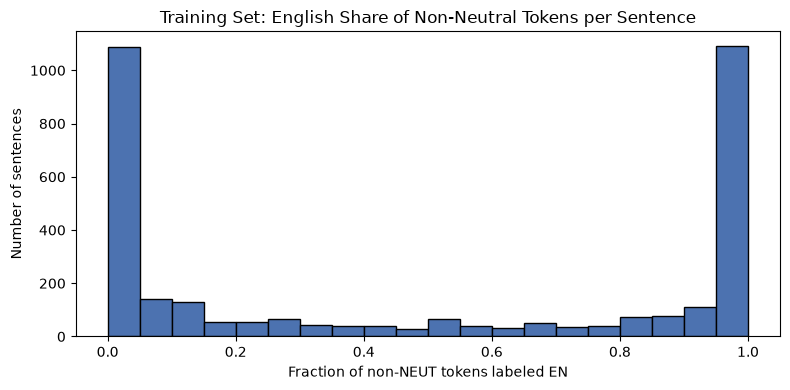

In [13]:
fig, ax = plt.subplots()
ax.hist(switch_dfs["train"]["en_share"].dropna(), bins=20, color="#4C72B0", edgecolor="black")
ax.set_title("Training Set: English Share of Non-Neutral Tokens per Sentence")
ax.set_xlabel("Fraction of non-NEUT tokens labeled EN")
ax.set_ylabel("Number of sentences")
plt.tight_layout()
plt.show()


## 9. Cross-Check Against the Raw-Corpus Conversion Counts

`src/corpus_converter.py` reported 73,656 retained tokens when converting the raw corpus. Since
`src/preprocess.py` only cleans and splits that already-converted data (it does not drop
tokens further, aside from stripping empty strings), the combined token count across all three
processed splits should match.

In [14]:
total_processed_tokens = sum(token_totals.values())
print(f"train + val + test tokens: {total_processed_tokens}")
print("Expected (from corpus_converter.py's retained-token count): 73656")
print("Match:", total_processed_tokens == 73656)


train + val + test tokens: 73656
Expected (from corpus_converter.py's retained-token count): 73656
Match: True


## Summary

- Schema checks passed: every record's `tokens`/`labels` lengths match and all labels are valid
  (`DE`/`EN`/`NEUT`).
- No Reddit comment appears in more than one split - the comment-level split required by the
  project paper is intact.
- Label proportions are broadly consistent across train/val/test, so the random comment-level
  split did not introduce an obvious label-distribution skew.
- Training-token length is well covered by `max_word_len=20`; only a tiny fraction of tokens are
  truncated.
- The training character vocabulary (159 entries) covers ASCII letters/digits/punctuation, German
  umlauts/?, and a long tail of other Unicode (emoji, accented loanwords, etc.) picked up from
  Reddit text; val/test out-of-vocabulary character rates are reported above.
- Code-switching is substantial and consistent across splits (~35-40% of sentences mix German and
  English), with most code-switched sentences containing only one or two switch points - matching
  Osmelak & Wintner's (2023) finding that switches are typically short insertions rather than
  pervasive mixing.
- Processed token totals reconcile exactly with the raw-corpus conversion counts, confirming
  `preprocess.py` did not silently drop additional data.